使用フォント: Noto Sans CJK JP
データ形状: (206, 58)
文章数: 20
特徴量数: 53
相関行列に使用した文章数: 20
平均相関行列を保存しました。


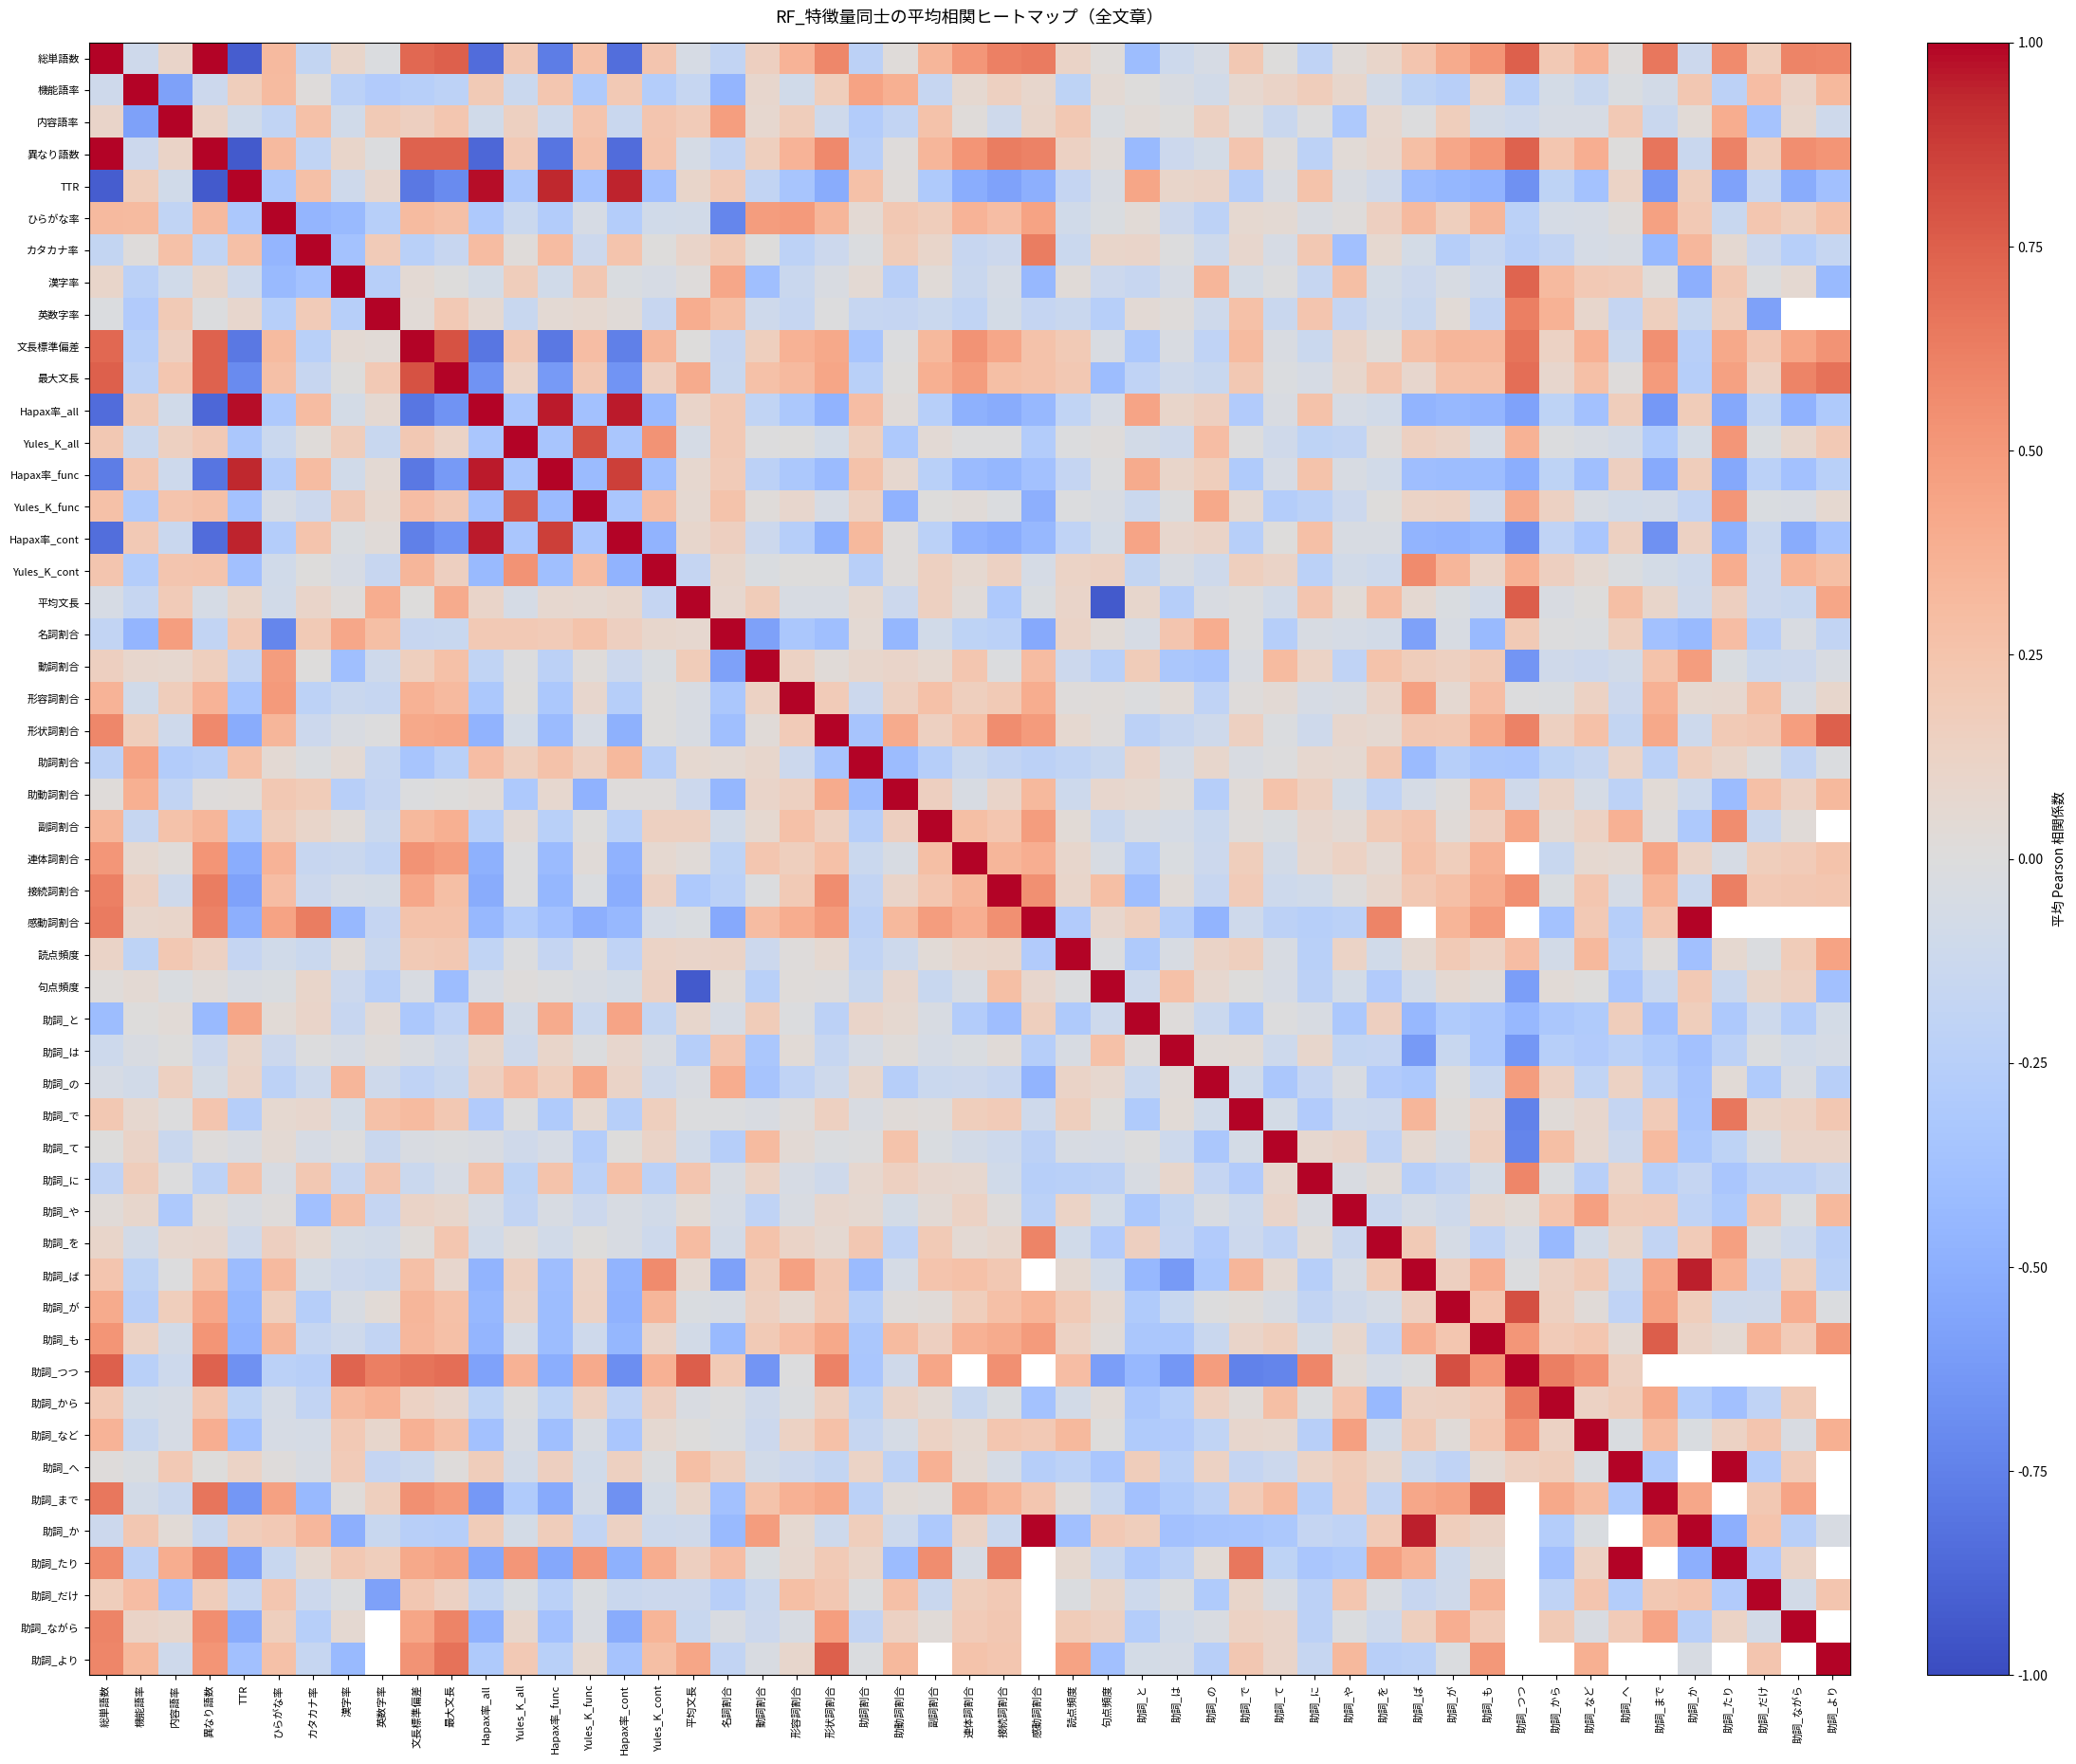

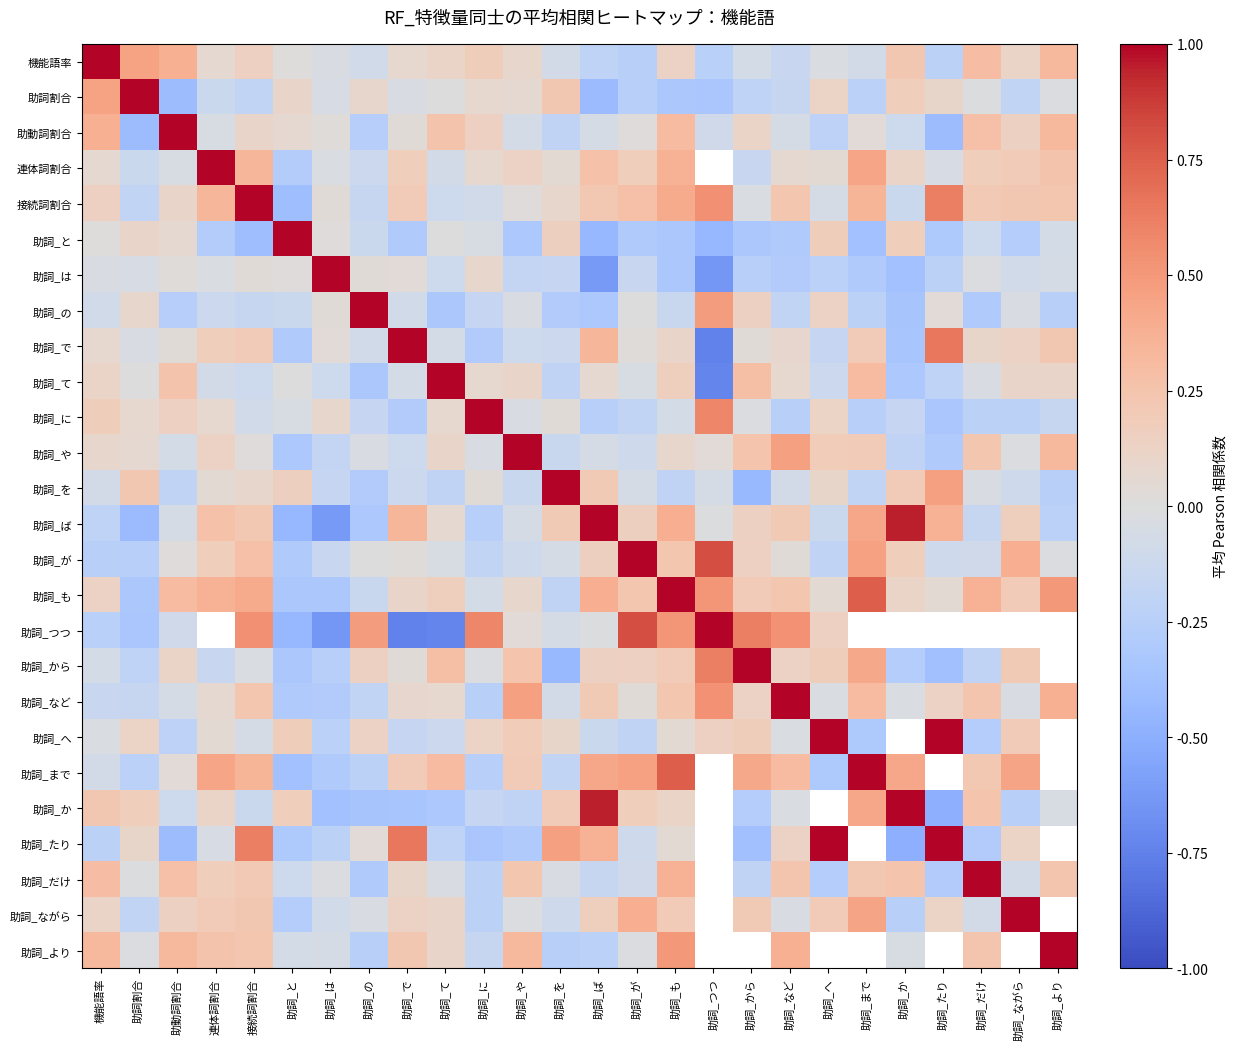

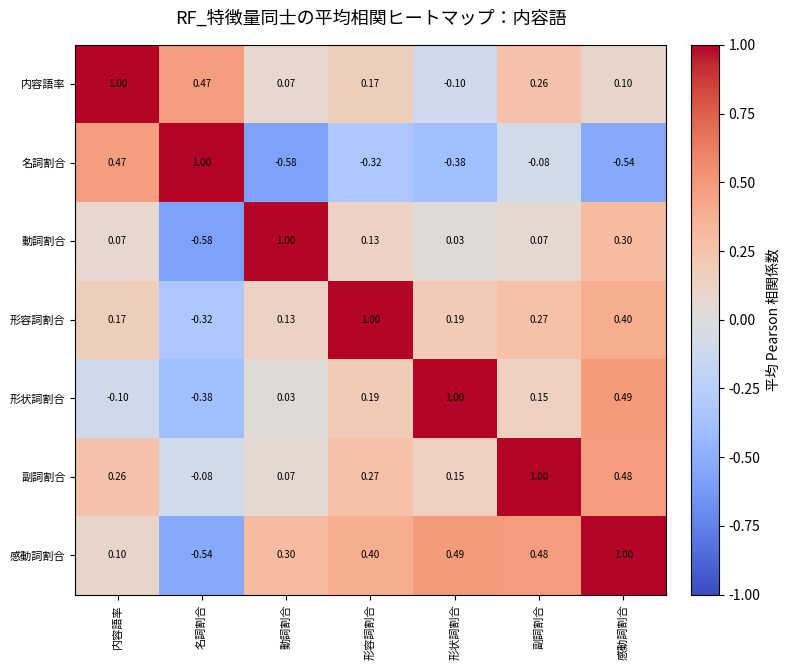

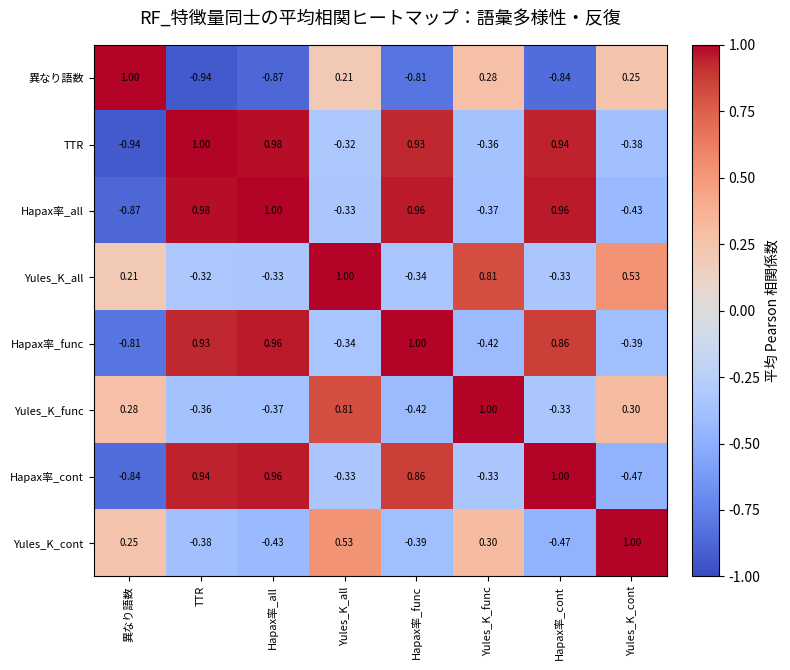

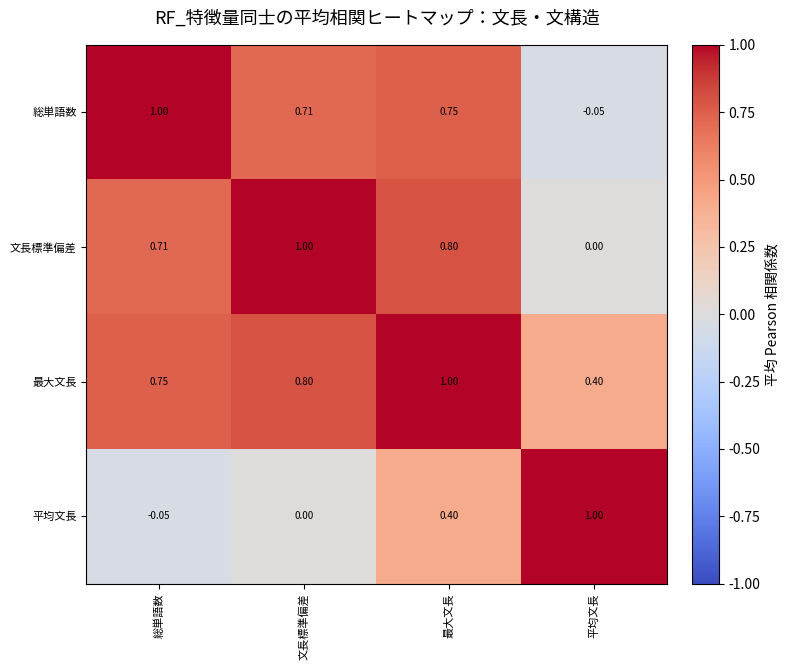

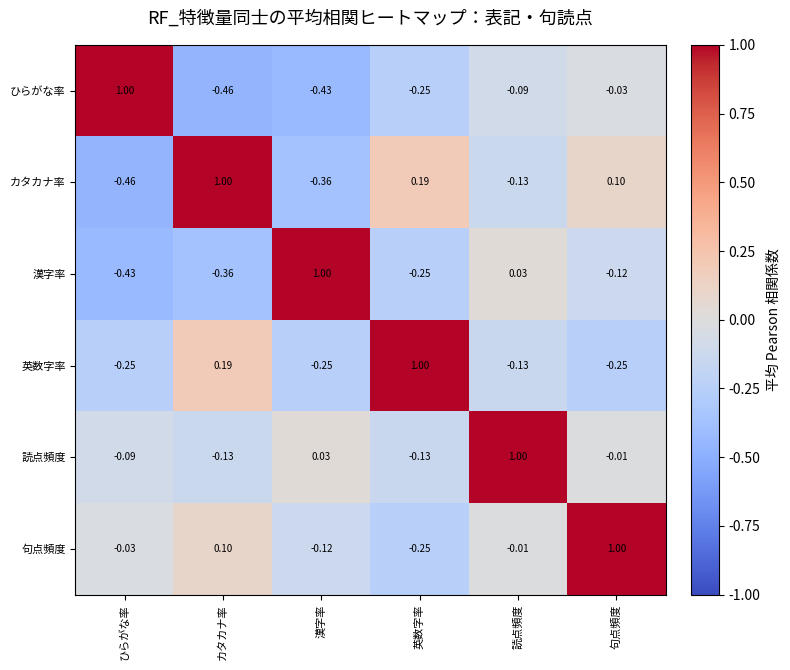


処理完了
出力先: /workspace/研究/one-sentence/AI確信度/RF_特徴量同士の相関ヒートマップ


In [9]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Noto Sans CJK JP"
plt.rcParams["axes.unicode_minus"] = False

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 日本語フォントを探す
candidates = [
    "Noto Sans CJK JP",
    "IPAexGothic",
    "IPAGothic",
    "Yu Gothic",
    "Meiryo"
]

available_fonts = {f.name for f in fm.fontManager.ttflist}

for font in candidates:
    if font in available_fonts:
        plt.rcParams["font.family"] = font
        print("使用フォント:", font)
        break
else:
    print("日本語フォントが見つかりません。インストールが必要です。")

plt.rcParams["axes.unicode_minus"] = False
# =========================
# 1. 入出力設定
# =========================
input_path = "RF_predict_proba_cumulative_features_merged.csv"

output_dir = "RF_特徴量同士の相関ヒートマップ"
os.makedirs(output_dir, exist_ok=True)

df = pd.read_csv(input_path)

# メタデータ・AI確率は除外し、特徴量だけを対象にする
exclude_cols = ["doc_id", "label", "sent_order", "AI確率"]
feature_cols = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if col not in exclude_cols
]

print("データ形状:", df.shape)
print("文章数:", df["doc_id"].nunique())
print("特徴量数:", len(feature_cols))


# =========================
# 2. 特徴量グループ
# =========================
feature_groups = {
    "機能語": [
        "機能語率", "助詞割合", "助動詞割合", "連体詞割合",
        "接続詞割合", "助詞_と", "助詞_は", "助詞_の",
        "助詞_で", "助詞_て", "助詞_に", "助詞_や",
        "助詞_を", "助詞_ば", "助詞_が", "助詞_も",
        "助詞_つつ", "助詞_から", "助詞_など", "助詞_へ",
        "助詞_まで", "助詞_か", "助詞_たり", "助詞_だけ",
        "助詞_ながら", "助詞_より"
    ],
    "内容語": [
        "内容語率", "名詞割合", "動詞割合", "形容詞割合",
        "形状詞割合", "副詞割合", "感動詞割合"
    ],
    "語彙多様性・反復": [
        "異なり語数", "TTR", "Hapax率_all", "Yules_K_all",
        "Hapax率_func", "Yules_K_func",
        "Hapax率_cont", "Yules_K_cont"
    ],
    "文長・文構造": [
        "総単語数", "文長標準偏差", "最大文長", "平均文長"
    ],
    "表記・句読点": [
        "ひらがな率", "カタカナ率", "漢字率", "英数字率",
        "読点頻度", "句点頻度", "感嘆符数", "疑問符数"
    ]
}

# CSVに存在する特徴量だけを残す
feature_groups = {
    group: [f for f in features if f in feature_cols]
    for group, features in feature_groups.items()
}


# =========================
# 3. 文章ごとに相関行列を計算
# =========================
correlation_matrices = []
used_docs = []

for doc_id, doc_df in df.groupby("doc_id"):
    doc_df = doc_df.sort_values("sent_order")

    # 文章内の累積文数の変化を使って相関を計算
    X = doc_df[feature_cols].replace([np.inf, -np.inf], np.nan)

    # すべて欠損、または変動がない特徴量は相関を計算できない
    valid_cols = [
        col for col in feature_cols
        if X[col].notna().sum() >= 3 and X[col].nunique() > 1
    ]

    if len(doc_df) < 3 or len(valid_cols) < 2:
        continue

    corr = X[valid_cols].corr(method="pearson")

    # 全特徴量の並びを統一する
    corr = corr.reindex(
        index=feature_cols,
        columns=feature_cols
    )

    correlation_matrices.append(corr)
    used_docs.append(doc_id)

if not correlation_matrices:
    raise ValueError("相関行列を計算できる文章がありません。データを確認してください。")

# 各文章の相関係数を、特徴量ペアごとに平均する
mean_corr = pd.concat(
    correlation_matrices,
    keys=used_docs,
    names=["doc_id", "feature"]
).groupby(level="feature").mean()

mean_corr = mean_corr.reindex(
    index=feature_cols,
    columns=feature_cols
)

mean_corr.to_csv(
    os.path.join(output_dir, "特徴量同士の平均相関行列.csv"),
    encoding="utf-8-sig"
)

print("相関行列に使用した文章数:", len(used_docs))
print("平均相関行列を保存しました。")


# =========================
# 4. ヒートマップ描画関数
# =========================
def plot_heatmap(corr, title, save_path, annotate=False):
    # 全て欠損の行・列を除外
    corr = corr.dropna(axis=0, how="all").dropna(axis=1, how="all")

    if corr.empty:
        print("スキップ（有効な相関がありません）:", title)
        return

    n = len(corr.columns)
    fig_size = max(8, min(22, n * 0.48))

    fig, ax = plt.subplots(figsize=(fig_size, fig_size * 0.85))

    im = ax.imshow(
        corr.to_numpy(),
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        aspect="auto"
    )

    ax.set_xticks(range(n))
    ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(corr.index)))
    ax.set_yticklabels(corr.index, fontsize=8)

    ax.set_title(title, fontsize=13, pad=15)

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("平均 Pearson 相関係数")

    # 小規模なグループだけ数値を表示
    if annotate and n <= 15:
        for i in range(len(corr.index)):
            for j in range(len(corr.columns)):
                value = corr.iloc[i, j]
                if pd.notna(value):
                    ax.text(
                        j, i, f"{value:.2f}",
                        ha="center", va="center", fontsize=7
                    )

    plt.tight_layout()
    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()


# =========================
# 5. 全特徴量の平均ヒートマップ
# =========================
plot_heatmap(
    mean_corr,
    "RF_特徴量同士の平均相関ヒートマップ（全文章）",
    os.path.join(output_dir, "全特徴量_平均相関ヒートマップ.png")
)


# =========================
# 6. 特徴量グループ別ヒートマップ
# =========================
for group_name, features in feature_groups.items():
    if len(features) < 2:
        continue

    group_corr = mean_corr.loc[features, features]

    plot_heatmap(
        group_corr,
        f"RF_特徴量同士の平均相関ヒートマップ：{group_name}",
        os.path.join(output_dir, f"{group_name}_平均相関ヒートマップ.png"),
        annotate=True
    )

print("\n処理完了")
print("出力先:", os.path.abspath(output_dir))
